In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

In [2]:
#load the dataset

CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "tickets_en.csv"

tickets = pd.read_csv(DATA_PATH)

tickets.shape

(16338, 4)

In [3]:
tickets.head()

,subject,body,queue,text
0,Account Disruption,"Dear Customer Support Team,\n\nI am writing to...",Technical Support,"Account Disruption Dear Customer Support Team,..."
1,Query About Smart Home System Integration Feat...,"Dear Customer Support Team,\n\nI hope this mes...",Returns and Exchanges,Query About Smart Home System Integration Feat...
2,Inquiry Regarding Invoice Details,"Dear Customer Support Team,\n\nI hope this mes...",Billing and Payments,Inquiry Regarding Invoice Details Dear Custome...
3,Question About Marketing Agency Software Compa...,"Dear Support Team,\n\nI hope this message reac...",Sales and Pre-Sales,Question About Marketing Agency Software Compa...
4,Feature Query,"Dear Customer Support,\n\nI hope this message ...",Technical Support,"Feature Query Dear Customer Support,\n\nI hope..."


In [4]:
#train-test-split

X = tickets["text"]
y = tickets["queue"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

In [5]:
baseline_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            max_features=20000,
            ngram_range=(1, 2),
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            random_state=42,
        )
    )
])

In [7]:
baseline_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](10,)","['Billing and Payments','Customer Service','General Inquiry',..., 'Sales and Pre-Sales','Service Outages and Maintenance', 'Technical Support']"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",20000
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'


In [8]:
baseline_pred = baseline_model.predict(X_test)

In [9]:
baseline_accuracy = accuracy_score(y_test, baseline_pred)
baseline_macro_f1 = f1_score(
    y_test,
    baseline_pred,
    average="macro"
)

print(f"Baseline accuracy: {baseline_accuracy:.2%}")
print(f"Baseline Macro F1: {baseline_macro_f1:.3f}")

Baseline accuracy: 50.89%
Baseline Macro F1: 0.379


In [10]:
labels= sorted(y_test.unique())

labels

['Billing and Payments',
 'Customer Service',
 'General Inquiry',
 'Human Resources',
 'IT Support',
 'Product Support',
 'Returns and Exchanges',
 'Sales and Pre-Sales',
 'Service Outages and Maintenance',
 'Technical Support']

In [11]:
cm = confusion_matrix(
    y_test,
    baseline_pred,
    labels=labels
)

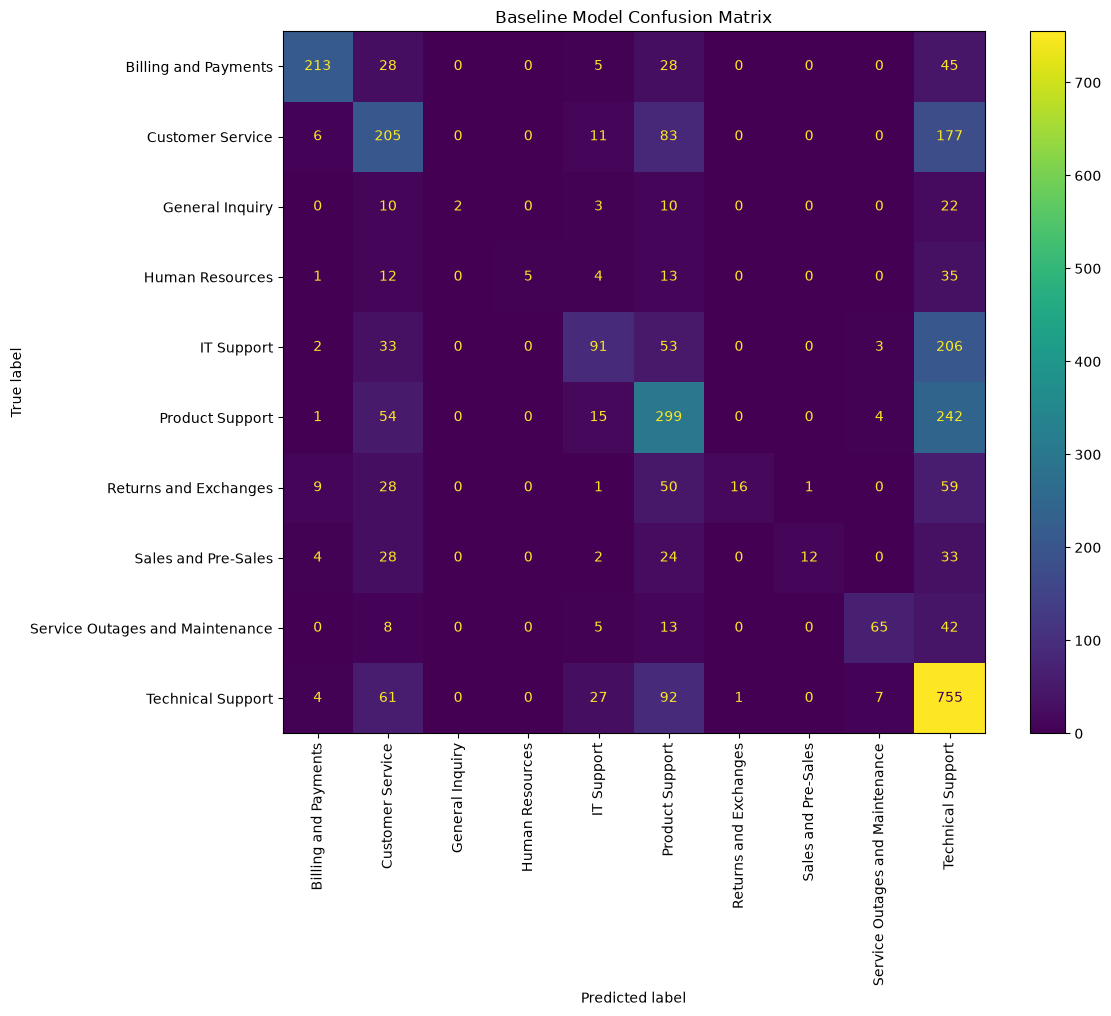

In [14]:
fig, ax = plt.subplots(figsize=(12, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(
    ax=ax,
    xticks_rotation= 90,
    values_format = "d"
)

plt.title("Baseline Model Confusion Matrix")
plt.tight_layout()
plt.show()

In [15]:
#Create an error-analysis DataFrame

results = pd.DataFrame({
    "text": X_test,
    "actual": y_test,
    "predicted": baseline_pred,
})

In [16]:
results.head()

,text,actual,predicted
995,Issue Encountered Assistance Needed,Technical Support,Product Support
11148,Hospital Systems Data Breach Notification In r...,Technical Support,Technical Support
12395,Problem with Synchronization Across Various De...,Technical Support,Technical Support
1840,Request for Assistance with Software Crashes T...,IT Support,Technical Support
11345,The system encountered a data breach. We have...,Technical Support,Technical Support


In [17]:
errors = results[
    results["actual"] != results["predicted"]
    ].copy()

In [19]:
errors.shape

(1605, 3)

In [20]:
len(results)

3268

In [21]:
len(errors)

1605

In [24]:
#Find the most common confusion pairs

confusion_pairs = (
    errors
    .groupby(["actual","predicted"])
    .size()
    .reset_index(name= "count")
    .sort_values("count", ascending = False)
)

confusion_pairs.head(10)

,actual,predicted,count
26,Product Support,Technical Support,242
21,IT Support,Technical Support,206
7,Customer Service,Technical Support,177
45,Technical Support,Product Support,92
6,Customer Service,Product Support,83
43,Technical Support,Customer Service,61
32,Returns and Exchanges,Technical Support,59
23,Product Support,Customer Service,54
19,IT Support,Product Support,53
30,Returns and Exchanges,Product Support,50


In [25]:
#Inspect actual mistakes

errors[
    (errors["actual"] == "IT Support") &
    (errors["predicted"] == "Technical Support")
    ][["text","actual","predicted"]].head(10)

,text,actual,predicted
1840,Request for Assistance with Software Crashes T...,IT Support,Technical Support
4008,Software Malfunction The digital marketing cam...,IT Support,Technical Support
10444,Protecting Medical Data in Docker Environments...,IT Support,Technical Support
7842,Secure Management of Medical Data with OBS Stu...,IT Support,Technical Support
11400,Challenges with Digital Marketing Tools Our di...,IT Support,Technical Support
2704,Issue with Intermittent Slow Loading in Projec...,IT Support,Technical Support
13487,Crash in Data Analytics Platform The data anal...,IT Support,Technical Support
134,Question About Integration Procedures and Best...,IT Support,Technical Support
8707,I am sorry to hear that you are experiencing ...,IT Support,Technical Support
15109,Request for Assistance with Unauthorized Data ...,IT Support,Technical Support


In [27]:
#Inspect one badly performing minority class

errors[
    errors["actual"] == "General Inquiry"
    ]["predicted"].value_counts()

predicted
Technical Support    22
Product Support      10
Customer Service     10
IT Support            3
Name: count, dtype: int64

In [28]:
errors[
    errors["actual"] == "Human Resources"
]["predicted"].value_counts()

predicted
Technical Support       35
Product Support         13
Customer Service        12
IT Support               4
Billing and Payments     1
Name: count, dtype: int64

In [29]:
errors[
    errors["actual"] == "Returns and Exchanges"
]["predicted"].value_counts()

predicted
Technical Support       59
Product Support         50
Customer Service        28
Billing and Payments     9
IT Support               1
Sales and Pre-Sales      1
Name: count, dtype: int64

In [31]:
#try class-weighted Logistic Regression

balanced_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            max_features=20000,
            ngram_range= (1,2),
        )
    ),
    (
        "classifier", 
        LogisticRegression(
            max_iter=1000,
            random_state=42,
            class_weight="balanced",
        )
    )
])

In [32]:
class_weight= "balanced"

In [33]:
balanced_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](10,)","['Billing and Payments','Customer Service','General Inquiry',..., 'Sales and Pre-Sales','Service Outages and Maintenance', 'Technical Support']"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",20000
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'


In [34]:
balanced_pred = balanced_model.predict(X_test)

In [35]:
balanced_accuracy = accuracy_score(
    y_test,
    balanced_pred
)

balanced_macro_f1 = f1_score(
    y_test,
    balanced_pred,
    average="macro"
)

print(f"Balanced accuracy: {balanced_accuracy:.2%}")
print(f"Balanced Macro F1: {balanced_macro_f1:.3f}")

Balanced accuracy: 51.04%
Balanced Macro F1: 0.514


In [36]:
print(
    classification_report(
        y_test,
        balanced_pred
    )
)

                                 precision    recall  f1-score   support

           Billing and Payments       0.79      0.75      0.77       319
               Customer Service       0.45      0.43      0.44       482
                General Inquiry       0.36      0.64      0.46        47
                Human Resources       0.42      0.63      0.51        70
                     IT Support       0.41      0.49      0.45       388
                Product Support       0.48      0.40      0.43       615
          Returns and Exchanges       0.40      0.49      0.44       164
            Sales and Pre-Sales       0.33      0.66      0.44       103
Service Outages and Maintenance       0.57      0.79      0.66       133
              Technical Support       0.60      0.49      0.54       947

                       accuracy                           0.51      3268
                      macro avg       0.48      0.58      0.51      3268
                   weighted avg       0.53      0

In [37]:
#Compare the two models directly

comparison = pd.DataFrame({
    "Model": [
        "Baseline Logistic Regression",
        "Balanced Logistic Regression"
    ],
    "Accuracy": [
        baseline_accuracy,
        balanced_accuracy
    ],
    "Macro F1": [
        baseline_macro_f1,
        balanced_macro_f1
    ],
})

comparison

,Model,Accuracy,Macro F1
0,Baseline Logistic Regression,0.508874,0.379203
1,Balanced Logistic Regression,0.510404,0.514038


## Class Weighting Experiment

The baseline Logistic Regression model achieved 50.89% accuracy and a Macro F1 score of 0.379.

Because exploratory analysis revealed strong class imbalance, a second Logistic Regression model was trained using balanced class weights.

The balanced model achieved 51.04% accuracy and a Macro F1 score of 0.514.

Class weighting therefore substantially improved performance across classes without reducing overall accuracy, confirming that class imbalance was a major limitation of the original baseline.

The balanced Logistic Regression model is currently the preferred classifier.

In [38]:
print(
    classification_report(
        y_test,
        balanced_pred
    )
)

                                 precision    recall  f1-score   support

           Billing and Payments       0.79      0.75      0.77       319
               Customer Service       0.45      0.43      0.44       482
                General Inquiry       0.36      0.64      0.46        47
                Human Resources       0.42      0.63      0.51        70
                     IT Support       0.41      0.49      0.45       388
                Product Support       0.48      0.40      0.43       615
          Returns and Exchanges       0.40      0.49      0.44       164
            Sales and Pre-Sales       0.33      0.66      0.44       103
Service Outages and Maintenance       0.57      0.79      0.66       133
              Technical Support       0.60      0.49      0.54       947

                       accuracy                           0.51      3268
                      macro avg       0.48      0.58      0.51      3268
                   weighted avg       0.53      0

In [39]:
from pathlib import Path
import joblib

# Locate the project root
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

# Create a folder for trained models
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)

# Define where the model will be saved
MODEL_PATH = MODEL_DIR / "queue_classifier.joblib"

# Save our trained balanced model
joblib.dump(balanced_model, MODEL_PATH)

print("Model saved successfully!")
print(MODEL_PATH)

Model saved successfully!
/Users/rinkuta/Projects/support-ticket-ai-copilot/models/queue_classifier.joblib


In [40]:
# Load the saved model
loaded_model = joblib.load(MODEL_PATH)

# Test on a new customer ticket
new_ticket = [
    "I was charged twice for my subscription. "
    "Please refund the duplicate payment."
]

prediction = loaded_model.predict(new_ticket)

print("Predicted queue:", prediction[0])

Predicted queue: Billing and Payments
